# SIIM-ISIC Melanoma Classification: CNN + LIME

Melanoma is the deadliest skin cancer, yet caught early its 5-year survival is above 99%. A dermatologist looks at a mole through a dermatoscope and decides: biopsy or not. This notebook asks whether a CNN can make that call from the image alone, and whether we can see **why** it decides.

**Objectives**
1. How rare is melanoma here, and what does that do to the metric?
2. Which patient groups carry more risk?
3. Which traps (leakage, shortcuts) could make a model look better than it is?
4. Can a pre-trained CNN separate benign from malignant lesions?
5. Does the CNN look at the lesion, or at something else?

**Data** → [Kaggle competition](https://www.kaggle.com/competitions/siim-isic-melanoma-classification) · 33,126 labelled images from 2,056 patients · 10,982 unlabelled test images

<!-- objective -->
## Objective

- **Problem** → melanoma is the deadliest skin cancer but is curable when caught early; dermatologists see far more harmless moles than melanomas (1 in 57 images here), and waiting lists are long
- **Why this repo** → rank skin-lesion photos by P(malignant) with a fine-tuned CNN, judge it with ROC-AUC instead of the misleading 98 % accuracy, and check with LIME that it looks at the lesion, not at hair, rulers or the camera
- **Real-world use** → triage in teledermatology: suspicious photos reach the dermatologist first, low-risk ones wait; the LIME map shows *where* the model looked

# [1/11] Setup

Set every knob once in the top cell → later cells only read them, and nothing is written by default

In [ ]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/16] DATA_DIR: competition data folder
    Default = '/kaggle/input/siim-isic-melanoma-classification'
[2/16] WORK_DIR: folder for cache, model and submission files
    Default = '/kaggle/working'
[3/16] IMG_SIZE: image size in pixels
    Default = 224
    For example:
        IMG_SIZE = 160
[4/16] N_BENIGN: benign images sampled (all malignant images are used)
    Default = 5000
    For example:
        N_BENIGN = 1000
        N_BENIGN = 8000
[5/16] AUG_PER_MALIGNANT: augmented copies made of each training malignant image
    Default = 2
    For example:
        AUG_PER_MALIGNANT = 0
[6/16] N_JOBS: threads for reading JPEGs
    Default = 4
[7/16] BATCH_SIZE: images per training step
    Default = 32
[8/16] EPOCHS_HEAD: max epochs while the backbone is frozen
    Default = 10
[9/16] EPOCHS_FINE_TUNE: max epochs while fine-tuning
    Default = 8
[10/16] FINE_TUNE_LAST_N: backbone layers unfrozen when fine-tuning
    Default = 20
[11/16] LIME_SAMPLES: perturbed images per LIME explanation
    Default = 300
    For example:
        LIME_SAMPLES = 1000
[12/16] SEED: random seed
    Default = 42
[13/16] WRITE_CACHE: save loaded images as .npz for faster re-runs
    Default = False
[14/16] SAVE_MODEL: save the trained model
    Default = False
[15/16] SAVE_SUBMISSION: predict all test images and write submission.csv
    Default = False
    For example:
        SAVE_SUBMISSION = True
[16/16] DISPLAY_SEED: which images are shown in the example grids (None = a new random sample on every run)
    Default = None
    For example:
        DISPLAY_SEED = 7
"""
DATA_DIR           = '/kaggle/input/siim-isic-melanoma-classification'
WORK_DIR           = '/kaggle/working'
IMG_SIZE           = 224
N_BENIGN           = 5000
AUG_PER_MALIGNANT  = 2
N_JOBS             = 4
BATCH_SIZE         = 32
EPOCHS_HEAD        = 10
EPOCHS_FINE_TUNE   = 8
FINE_TUNE_LAST_N   = 20
LIME_SAMPLES       = 300
DISPLAY_SEED       = None
SEED               = 42
WRITE_CACHE        = False
SAVE_MODEL         = False
SAVE_SUBMISSION    = False

JPEG_DIR           = f'{DATA_DIR}/jpeg'
CACHE_FILE         = f'{WORK_DIR}/sample_{IMG_SIZE}.npz'
MODEL_FILE         = f'{WORK_DIR}/melanoma_effnetb0.keras'
SUBMISSION_FILE    = f'{WORK_DIR}/submission.csv'
SUBMISSION_PREVIEW = 16
PAD                = 28
PALETTE            = {0: 'black', 1: 'red'}
CLASS_NAMES        = {0: 'benign', 1: 'malignant'}

In [ ]:
%pip install -q lime
import os
import gc
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from lime import lime_image
from skimage.segmentation import mark_boundaries

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

keras.utils.set_random_seed(SEED)
sns.set_theme(style='whitegrid')

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')

show_rng = np.random.default_rng(DISPLAY_SEED)   # only decides which example images are displayed


# [2/11] Metadata

Load the CSVs and check for gaps → only 3 columns have small gaps

In [ ]:
from pathlib import Path


def find_competition_dir(default, required_column, root='/kaggle/input'):
    """Folder with train.csv + test.csv whose train.csv has `required_column`.
    Tries `default` first, then searches everything under `root` (Kaggle mount paths differ between setups)."""
    import csv
    candidates = [Path(default)]
    if Path(root).exists():
        candidates += sorted(p.parent for p in Path(root).rglob('train.csv'))
    for folder in candidates:
        if (folder / 'train.csv').is_file() and (folder / 'test.csv').is_file():
            with open(folder / 'train.csv', newline='') as fh:
                if required_column in next(csv.reader(fh)):
                    return str(folder)
    mounted = sorted(str(p) for p in Path(root).glob('*/*'))[:20] if Path(root).exists() else []
    raise FileNotFoundError(
        f"(!) No train.csv with a '{required_column}' column under {default} or {root}.\n"
        f"    Add Input -> Competitions -> {Path(default).name} (join the competition and accept its rules first)\n"
        f"    Mounted now: {mounted or 'nothing'}")


DATA_DIR = find_competition_dir(DATA_DIR, required_column='benign_malignant')
JPEG_DIR = f'{DATA_DIR}/jpeg'   # follow DATA_DIR if it was found elsewhere

train_df = pd.read_csv(f'{DATA_DIR}/train.csv')
test_df  = pd.read_csv(f'{DATA_DIR}/test.csv')
show_block('Outputs', {'train_df': train_df.shape, 'test_df': test_df.shape})

In [ ]:
display(train_df.head())

**Question:** What do we know about each image, and what is missing?
- `patient_id` → who the image belongs to
- `sex`, `age_approx` → patient sex and approximate age at imaging (rounded to 5 years)
- `anatom_site_general_challenge` → general body location of the lesion
- `diagnosis`, `benign_malignant`, `target` → the answer (train only)

**Answer:** Only three columns have gaps, all small: site 1.6% of train (3.2% of test), sex and age ~0.2% of train → we keep them as a `missing` group instead of dropping rows.

In [ ]:
missing = pd.DataFrame({
    'train missing': train_df.isna().sum(),
    'train %':       (train_df.isna().mean() * 100).round(2),
    'test missing':  test_df.isna().sum(),
    'test %':        (test_df.isna().mean() * 100).round(2),
})
display(missing[(missing['train missing'] > 0) | (missing['test missing'] > 0)])

# [3/11] Metadata EDA

Measure how rare melanoma is and who carries more risk → 1.76% overall, rising with age, highest on head/neck and in men

**Question:** How rare is melanoma?

**Answer:** Very rare: **584 of 33,126 images (1.76%)**, about 1 in 57.
→ A model that always says "benign" is 98.2% accurate and completely useless, like a smoke alarm that never rings. So models are judged by **ROC-AUC**, not accuracy (explained in [9/11]).

In [ ]:
counts = train_df['target'].value_counts().sort_index()
display(pd.DataFrame({'images': counts, 'share %': (counts / counts.sum() * 100).round(2)}).rename(index=CLASS_NAMES))

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index.map(CLASS_NAMES), counts.values, color=[PALETTE[0], PALETTE[1]])
for bar, n in zip(bars, counts.values):
    ax.annotate(f'{n:,}\n({n / counts.sum():.2%})', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')
ax.set_title('Target distribution (train)')
ax.set_ylabel('Images')
ax.margins(y=0.2)
plt.show()

**Question:** Can any column give the answer away?

**Answer:** Yes, `diagnosis`: every `melanoma` row is malignant, every other diagnosis is benign. It is written **after** the biopsy, so feeding it to a model is **target leakage**, like grading an exam with the answer key stapled to it → never a model input.

In [ ]:
display(pd.crosstab(train_df['diagnosis'], train_df['target'].map(CLASS_NAMES), margins=True)
        .sort_values('All', ascending=False))

**Question:** Which patient groups have a higher melanoma rate?

$$\hat p = \frac{k}{n}$$
- $\hat p$ → **malignancy rate**: share of the group's images that are malignant
- $k$ → malignant images in the group
- $n$ → all images in the group
- Analogy → a basketball free-throw percentage: 7 made of 10 shots = 70%

$$\text{CI}_{95\%} = \frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}$$
- $\text{CI}_{95\%}$ → **Wilson confidence interval**: the range that contains the true rate 95% of the time
- $z = 1.96$ → number of standard errors that covers 95%
- $n$ → group size: bigger group → narrower interval
- Analogy → 7 of 10 free throws could be a lucky day (true skill anywhere from 40% to 89%); 700 of 1,000 pins it between 67% and 73%

In [ ]:
def wilson_ci(k, n, z=1.96):
    p      = k / n
    denom  = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half   = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def malignancy_rate(groups, target):
    stats = (pd.DataFrame({'group': groups, 'target': target})
             .groupby('group', observed=True)['target'].agg(malignant='sum', images='size'))
    stats['rate %'] = stats['malignant'] / stats['images'] * 100
    lo, hi = wilson_ci(stats['malignant'], stats['images'])
    stats['ci low %'], stats['ci high %'] = lo * 100, hi * 100
    return stats.round(2)


def plot_malignancy_rate(stats, overall, ax, title):
    x = np.arange(len(stats))
    ax.bar(x, stats['rate %'], color=PALETTE[1], alpha=0.8)
    ax.errorbar(x, stats['rate %'], yerr=[stats['rate %'] - stats['ci low %'], stats['ci high %'] - stats['rate %']],
                fmt='none', ecolor='black', capsize=3)
    ax.axhline(overall * 100, color='grey', linestyle='--', label=f'overall {overall:.2%}')
    ax.set_xticks(x, [f'{g}\n(n={n:,})' for g, n in zip(stats.index, stats['images'])], rotation=45, ha='right')
    ax.set_ylabel('Malignant (%)')
    ax.set_title(title)
    ax.legend()

In [ ]:
age_bins = pd.cut(train_df['age_approx'], bins=[0, 30, 40, 50, 60, 70, 80, 100], right=False,
                  labels=['<30', '30-39', '40-49', '50-59', '60-69', '70-79', '80+'])
rate_tables = {
    'By anatomical site':    malignancy_rate(train_df['anatom_site_general_challenge'].fillna('missing'), train_df['target']),
    'By sex':                malignancy_rate(train_df['sex'].fillna('missing'), train_df['target']),
    'By approximate age':    malignancy_rate(age_bins.cat.add_categories('missing').fillna('missing'), train_df['target']),
}
for title, table in rate_tables.items():
    print(title)
    display(table)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, table) in zip(axes, rate_tables.items()):
    plot_malignancy_rate(table, train_df['target'].mean(), ax, title)
plt.tight_layout()
plt.show()

**Answer:**
- **Age** is the strongest signal: ~1% below 50 → 2.3% in the 60s → 4.1% in the 70s → **9.4% at 80+** (CI 7.4-11.9%)
- **Site:** head/neck is highest at **4.0%** (CI 3.2-5.0%); oral/genital looks high (3.2%) but has only 124 images → CI 1.3-8.0% → can't tell
- **Sex:** male 2.1% vs female 1.4%, intervals don't overlap → real but small

→ Metadata carries signal. The image-only CNN ignores it for now (see Next steps).

**Question:** Can the same patient end up in both training and evaluation data?

**Answer:** Easily: 2,056 patients share 33,126 images (median 12 each, max 115) and 428 of them have at least one malignant image. The official test set has **0%** patient overlap with train.
→ If one patient's moles sat on both sides of our split, the CNN could recognise the **person** (skin tone, camera, lighting), like a teacher who recognises handwriting instead of grading the answer → we split **by patient** in [4/11].

In [ ]:
per_patient = train_df.groupby('patient_id').agg(images=('image_name', 'size'), malignant=('target', 'sum'))
display(pd.DataFrame({'value': {
    'patients in train':                 f"{len(per_patient):,}",
    'images per patient (median)':       f"{per_patient['images'].median():.0f}",
    'images per patient (max)':          f"{per_patient['images'].max()}",
    'patients with a malignant image':   f"{(per_patient['malignant'] > 0).sum():,}",
    'test patients also in train':       f"{test_df['patient_id'].isin(train_df['patient_id']).mean():.1%}",
}}))

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(per_patient['images'], bins=range(1, per_patient['images'].max() + 2), color='grey')
ax.set_xlabel('Images per patient')
ax.set_ylabel('Patients')
ax.set_title('Images per patient (train)')
plt.show()

# [4/11] Sampling and split

Draw a lighter sample and split it by patient → 5,584 images, ~70 / 15 / 15, no patient in two splits

**Question:** How do we train on 584 malignant images without drowning them in 32,542 benign ones, and without loading all 33,126 JPEGs?

**Answer:** Sample: keep **all 584** malignant images and draw `N_BENIGN` = **5,000** random benign images, without replacement.

| Subset | Benign | Malignant | Malignant % |
|---|---|---|---|
| Original | 32,542 | 584 | 1.76 |
| Sampled | 5,000 | 584 | 10.46 |

→ 6× lighter than the full set, yet 3.5× more images than a 1,000-benign sample, so the CNN sees far more normal skin. Evaluation runs at ~10% malignant instead of 1.76%, which still flatters precision a little (see [9/11]).

In [ ]:
def sampling(df, target_col, class_distribution_dict, seed=SEED):
    parts = [df[df[target_col] == cls].sample(n=min(count, (df[target_col] == cls).sum()), random_state=seed)
             for cls, count in class_distribution_dict.items()]
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)


sample_df = sampling(train_df, 'target', {0: N_BENIGN, 1: int(train_df['target'].sum())})
display(sample_df['target'].value_counts().rename(index=CLASS_NAMES).to_frame('images'))

In [ ]:
display(sample_df.head())

**Question:** How do we get honest validation and test sets?

**Answer:** `StratifiedGroupKFold` puts each **patient** in exactly one split and keeps the class ratio similar: ~1/7 of patients → test, ~1/6 of the rest → validation → about **70 / 15 / 15**: train 3,986 images (416 malignant), validation 797 (83), test 801 (85). An assertion stops the notebook if any patient lands in two splits.

In [ ]:
def grouped_split(df, n_splits, target_col='target', group_col='patient_id', seed=SEED):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest_pos, holdout_pos = next(sgkf.split(df, df[target_col], groups=df[group_col]))
    return df.index[rest_pos], df.index[holdout_pos]


trainval_idx, test_idx = grouped_split(sample_df, n_splits=7)
train_idx, val_idx     = grouped_split(sample_df.loc[trainval_idx], n_splits=6)
splits   = {'train': train_idx, 'val': val_idx, 'test': test_idx}
patients = {name: set(sample_df.loc[idx, 'patient_id']) for name, idx in splits.items()}

overlap = (patients['train'] & patients['val']) | (patients['train'] & patients['test']) | (patients['val'] & patients['test'])
assert not overlap, f'(!) {len(overlap)} patients appear in more than one split'

display(pd.DataFrame({name: {'images':      len(idx),
                             'patients':    len(patients[name]),
                             'malignant':   int(sample_df.loc[idx, 'target'].sum()),
                             'malignant %': round(sample_df.loc[idx, 'target'].mean() * 100, 1)}
                      for name, idx in splits.items()}).T.astype({'images': int, 'patients': int, 'malignant': int}))

# [5/11] Load images

Turn the sampled JPEGs into arrays quickly → draft-mode decoding, ~800 MB in memory

**Question:** How do we turn 5,584 JPEGs (up to ~6000×4000 px) into model input without waiting minutes?

**Answer:** Read each JPEG into a NumPy array of shape `(IMG_SIZE, IMG_SIZE, 3)`: height × width × RGB channels, values 0-255.
- **Draft mode** → the JPEG decoder decodes at 1/2, 1/4 or 1/8 scale directly, like reading a book's chapter summaries instead of every page
- **Threads** → `N_JOBS` images decoded at the same time
- **Cache** → optional `.npz` file (`WRITE_CACHE`) so re-runs skip this step

In [ ]:
def load_image(path, size=IMG_SIZE):
    with Image.open(path) as image:
        image.draft('RGB', (size, size))
        return np.asarray(image.convert('RGB').resize((size, size)))


def load_images(image_names, subset='train', size=IMG_SIZE, cache_file=None, step='[1.1]'):
    names = np.asarray(image_names).astype(str)
    if cache_file and os.path.exists(cache_file):
        with np.load(cache_file) as cached:
            if np.array_equal(cached['names'], names) and cached['X'].shape[1] == size:
                print(f'{step} Loaded from cache → {cache_file}')
                return cached['X']

    paths = [f'{JPEG_DIR}/{subset}/{name}.jpg' for name in names]
    with ThreadPoolExecutor(max_workers=N_JOBS) as pool:
        X = np.stack(list(tqdm(pool.map(lambda p: load_image(p, size), paths),
                               total=len(paths), desc=f'{step} Loading {subset} images')))
    if cache_file and WRITE_CACHE:
        np.savez(cache_file, X=X, names=names)
        print(f'{step} Cache written → {cache_file}')
    return X

In [ ]:
show_block('Inputs', {
    'images':       f'{len(sample_df):,}',
    'size':         f'{IMG_SIZE}x{IMG_SIZE}',
    'threads':      N_JOBS,
    'cache file':   CACHE_FILE,
    'cache exists': os.path.exists(CACHE_FILE),
    'write cache':  WRITE_CACHE,
})

In [ ]:
X_all = load_images(sample_df['image_name'], cache_file=CACHE_FILE)
y_all = sample_df['target'].to_numpy()
show_block('Outputs', {'X_all': X_all.shape, 'y_all': y_all.shape, 'memory': f'{X_all.nbytes / 1024**2:.0f} MB'})

# [6/11] Image EDA

Look at the lesions and hunt for shortcuts → artifacts, resolution and colour per class

**Question:** What do the lesions look like?

**What to look for** → hair, rulers, ink marks, dark circular corners (the dermatoscope's vignette). These are **artifacts**: if they show up more in one class, the CNN may learn them instead of the lesion.

In [ ]:
fig, axes = plt.subplots(4, 8, figsize=(17.6, 10.4))
for cls, rows in [(0, axes[:2]), (1, axes[2:])]:
    for ax, i in zip(rows.ravel(), show_rng.choice(np.flatnonzero(y_all == cls), rows.size, replace=False)):
        ax.imshow(X_all[i])
        ax.set_title(f"{CLASS_NAMES[cls]}\n{sample_df.loc[i, 'anatom_site_general_challenge']}, {sample_df.loc[i, 'age_approx']:.0f}",
                     fontsize=8, color=PALETTE[cls])
        ax.axis('off')
plt.suptitle('Random benign (top two rows) and malignant (bottom two rows) images', fontweight='bold')
plt.tight_layout()
plt.show()

**Question:** Could image resolution give the label away?

Resolution is a fingerprint of the clinic and camera. If some resolutions are mostly malignant, the CNN can partly learn the **acquisition source** (borders, blur, colour profile), like guessing a letter's content from its envelope.

**Answer:** _after the first run_ → read the `malignant %` column: rows far from the ~10% sample average flag a possible shortcut.

In [ ]:
def original_size(name):
    with Image.open(f'{JPEG_DIR}/train/{name}.jpg') as image:
        return f'{image.size[0]}x{image.size[1]}'


resolution = sample_df['image_name'].map(original_size)
res_table  = pd.crosstab(resolution, sample_df['target'].map(CLASS_NAMES))
res_table['total']       = res_table.sum(axis=1)
res_table['malignant %'] = (res_table['malignant'] / res_table['total'] * 100).round(1)
display(res_table.sort_values('total', ascending=False).head(10))

**Question:** Do malignant lesions differ in colour or contrast?
- **Mean R / G / B** → average brightness of each colour channel in one image
- **Contrast (std)** → how far pixel values spread from the image's average: plain skin → low, dark lesion on light skin → high
- Each class is normalised separately → the smaller malignant class isn't flattened

**Answer:** _after the first run_ → a clear shift = colour cues the CNN can use, or camera differences (compare with the resolution table).

In [ ]:
channel_means = X_all.reshape(len(X_all), -1, 3).mean(axis=1)
colour_df = pd.DataFrame({
    'mean red':       channel_means[:, 0],
    'mean green':     channel_means[:, 1],
    'mean blue':      channel_means[:, 2],
    'contrast (std)': [img.std() for img in X_all],
    'class':          pd.Series(y_all).map(CLASS_NAMES),
})
display(colour_df.groupby('class').median().round(1))

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ['mean red', 'mean green', 'mean blue', 'contrast (std)']):
    sns.kdeplot(data=colour_df, x=col, hue='class', common_norm=False, fill=True, ax=ax,
                palette={'benign': PALETTE[0], 'malignant': PALETTE[1]})
    ax.set_title(col)
plt.tight_layout()
plt.show()

# [7/11] Hair removal and augmentation

Remove hair and add varied malignant copies to the training split only → 1,248 malignant vs 3,570 benign, the rest handled by class weights

**Question:** Hair crosses many lesions. Can we remove it before it confuses the CNN?

**Answer:** Yes, with morphology + inpainting, in 5 steps:

1. **Grayscale** → one brightness channel; hair is dark on lighter skin
2. **Kernel (structuring element)** → a small shape that slides over the image like a stamp; we use a 17×17 rectangle

    ```
    MORPH_RECT   MORPH_ELLIPSE   MORPH_CROSS     (5×5 examples)
    1 1 1 1 1    0 0 1 0 0       0 0 1 0 0
    1 1 1 1 1    1 1 1 1 1       0 0 1 0 0
    1 1 1 1 1    1 1 1 1 1       1 1 1 1 1
    1 1 1 1 1    1 1 1 1 1       0 0 1 0 0
    1 1 1 1 1    0 0 1 0 0       0 0 1 0 0
    ```
3. **Blackhat**

    $$B = (I \oplus K) \ominus K - I$$
    - $I$ → grayscale image, $K$ → kernel
    - $\oplus$ → **dilation**: each pixel takes the brightest value under the kernel → thin dark hairs disappear
    - $\ominus$ → **erosion**: each pixel takes the darkest value → shapes shrink back to their size
    - $(I \oplus K) \ominus K$ → **closing**: the image with thin dark gaps filled in
    - $B$ → what closing filled in = the hairs
    - Analogy → plaster the cracks in a wall, then compare with the original wall: only the cracks remain

    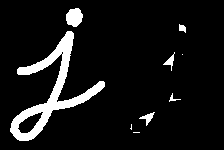
4. **Threshold**

    $$M(x, y) = \begin{cases} 255 & \text{if } B(x, y) > t \\ 0 & \text{otherwise} \end{cases}$$
    - $M$ → binary hair mask, $(x, y)$ → pixel position
    - $t = 5$ → minimum blackhat strength to count as hair
    - Analogy → a metal detector that beeps only above a set level

    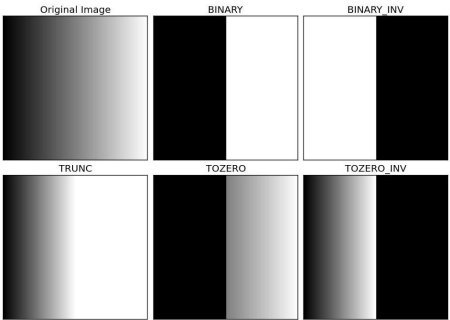
5. **Inpaint (Telea)** → fills each masked pixel from the edge inward with a weighted average of known neighbours, like a restorer retouching scratches on an old photo

    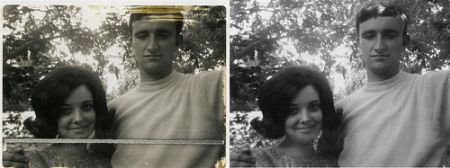

References → [Andrada's SIIM EDA](https://www.kaggle.com/code/andradaolteanu/siim-melanoma-competition-eda-augmentations) · [morphology](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html) · [thresholding](https://opencv24-python-tutorials.readthedocs.io/en/latest/py_tutorials/py_imgproc/py_thresholding/py_thresholding.html) · [inpainting](https://docs.opencv.org/3.4/df/d3d/tutorial_py_inpainting.html)

In [ ]:
def hair_remove(image, thresh=5, maxval=255):
    image    = np.asarray(image, dtype=np.uint8)
    gray     = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    kernel   = cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, mask  = cv2.threshold(blackhat, thresh, maxval, cv2.THRESH_BINARY)
    return cv2.inpaint(image, mask, 1, cv2.INPAINT_TELEA)


def transform_image(image, angle=10, scale=1.1):
    image  = np.asarray(image, dtype=np.uint8)
    h, w   = image.shape[:2]
    matrix = cv2.getRotationMatrix2D((w // 2, h // 2), np.random.uniform(-angle, angle), scale)
    return cv2.warpAffine(image, matrix, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)


def random_fscb(image):
    img = tf.image.convert_image_dtype(image, tf.float32)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_saturation(img, 0.7, 1.3)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    img = tf.image.random_brightness(img, 0.1)
    return tf.image.convert_image_dtype(tf.clip_by_value(img, 0.0, 1.0), tf.uint8).numpy()


def augment_images(X, y, n_sample, methods=(transform_image, random_fscb, hair_remove), seed=SEED):
    rng        = np.random.default_rng(seed)
    n_sample   = max(int(n_sample), 0)
    source     = rng.permutation(np.resize(np.arange(len(X)), n_sample))
    new_images = np.empty((n_sample, *X.shape[1:]), dtype=np.uint8)
    for i, idx in enumerate(tqdm(source, desc='[1.1] Augmenting')):
        new_images[i] = methods[rng.integers(len(methods))](X[idx])
    return new_images, np.asarray(y)[source]

**Question:** Training has 3,570 benign but only 416 malignant images. How do we stop the CNN from simply ignoring the rare class?

**Answer:** Two moves, both on the **training split only**, so nothing from validation/test leaks in.

**1. Over-sample with augmentation** → `AUG_PER_MALIGNANT` = 2 new, slightly different copies of each malignant image → 416 + 832 = **1,248**. Each copy = one training image + one random method:

| Method | Effect |
|---|---|
| `transform_image` | random rotation ±10° with ×1.1 zoom |
| `random_fscb` | random **f**lip, **s**aturation, **c**ontrast, **b**rightness |
| `hair_remove` | the same lesion without hair |

Capped at 2 copies: generating 3,000+ copies from 416 originals would teach the CNN the same few lesions over and over.

**1.1 Rotation + zoom** (`cv2.getRotationMatrix2D`) moves each pixel $(x, y)$ to $(x', y')$:

$$\begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} \alpha & \beta & (1-\alpha)\,c_x - \beta\,c_y \\ -\beta & \alpha & \beta\,c_x + (1-\alpha)\,c_y \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}, \qquad \alpha = s\cos\theta,\ \ \beta = s\sin\theta$$
- $\theta$ → rotation angle, random in $[-10°, +10°]$
- $s$ → scale: $1.1$ = zoom in 10%
- $(c_x, c_y)$ → image centre, the pin the photo spins around
- third column → shift that keeps the centre in place
- Analogy → a photo pinned at its centre on a turntable: turn it a little, then step 10% closer

**1.2 `cv2.warpAffine` options**
- **1.2.1 Interpolation** → rotated pixels land between old ones; how to fill them:
    - `INTER_NEAREST` → copy the closest pixel: fast, jagged edges
    - `INTER_LINEAR` → average the 4 nearest pixels: smooth (**used**)
    - `INTER_CUBIC` → 16 nearest: smoother, slower
    - `INTER_LANCZOS4` → 64 nearest: best for resizing, slowest
- **1.2.2 Border mode** → corners exposed by the rotation:
    - `BORDER_CONSTANT` → fill with black
    - `BORDER_REFLECT` → mirror the edge
    - `BORDER_WRAP` → wrap in from the opposite side
    - `BORDER_REPLICATE` → repeat the edge pixels: no black corners (**used**)

**2. Class weights** → the remaining gap (3,570 vs 1,248) is closed in the loss, not with more copies:

$$w_c = \frac{n}{2\,n_c}$$
- $w_c$ → weight of every image of class $c$ in the loss
- $n$ → all training images (4,818)
- $n_c$ → training images of class $c$: benign 3,570 → $w \approx 0.67$, malignant 1,248 → $w \approx 1.93$
- $2$ → number of classes, so a perfectly balanced set gets $w = 1$ for both
- Analogy → a town meeting with 3,570 locals and 1,248 newcomers: each newcomer's vote counts ~2.9× a local's, so both groups carry equal total say

References → [tf.image](https://www.tensorflow.org/api_docs/python/tf/image) · [OpenCV geometric transformations](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html)

In [ ]:
X_tr, y_tr   = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_te, y_te   = X_all[test_idx], y_all[test_idx]
show_block('Outputs', {
    'X_tr':  f'{X_tr.shape}  classes {np.bincount(y_tr)}',
    'X_val': f'{X_val.shape}  classes {np.bincount(y_val)}',
    'X_te':  f'{X_te.shape}  classes {np.bincount(y_te)}',
})

In [ ]:
preview = X_tr[show_rng.choice(np.flatnonzero(y_tr == 1), 6, replace=False)]
steps   = [('original', lambda img: img), ('hair_remove', hair_remove),
           ('transform_image', transform_image), ('random_fscb', random_fscb)]

fig, axes = plt.subplots(len(preview), len(steps), figsize=(12, 3 * len(preview)))
for row, img in enumerate(preview):
    for col, (name, fn) in enumerate(steps):
        axes[row, col].imshow(fn(img))
        axes[row, col].set_title(name if row == 0 else '')
        axes[row, col].axis('off')
plt.suptitle('Augmentation methods on training malignant images', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
n_to_generate = int((y_tr == 1).sum()) * AUG_PER_MALIGNANT
show_block('Inputs', {'malignant train images': int((y_tr == 1).sum()),
                      'copies per image':       AUG_PER_MALIGNANT,
                      'new images to generate': n_to_generate})

In [ ]:
X_tr_new, y_tr_new = augment_images(X_tr[y_tr == 1], y_tr[y_tr == 1], n_to_generate)
X_tr_bal = np.concatenate([X_tr, X_tr_new])
y_tr_bal = np.concatenate([y_tr, y_tr_new])
del X_tr_new, preview
gc.collect()
show_block('Outputs', {'X_tr_bal': X_tr_bal.shape, 'classes': np.bincount(y_tr_bal)})

In [ ]:
counts       = np.bincount(y_tr_bal)
class_weight = {cls: len(y_tr_bal) / (2 * n) for cls, n in enumerate(counts)}
display(pd.DataFrame({'images': counts, 'weight': [round(w, 3) for w in class_weight.values()]},
                     index=['benign', 'malignant']))

# [8/11] Modeling

Fine-tune a pre-trained EfficientNetB0 in two phases → the weights with the best validation AUC are kept

**Inside the model** → each layer of EfficientNetB0 and what its sub-modules do

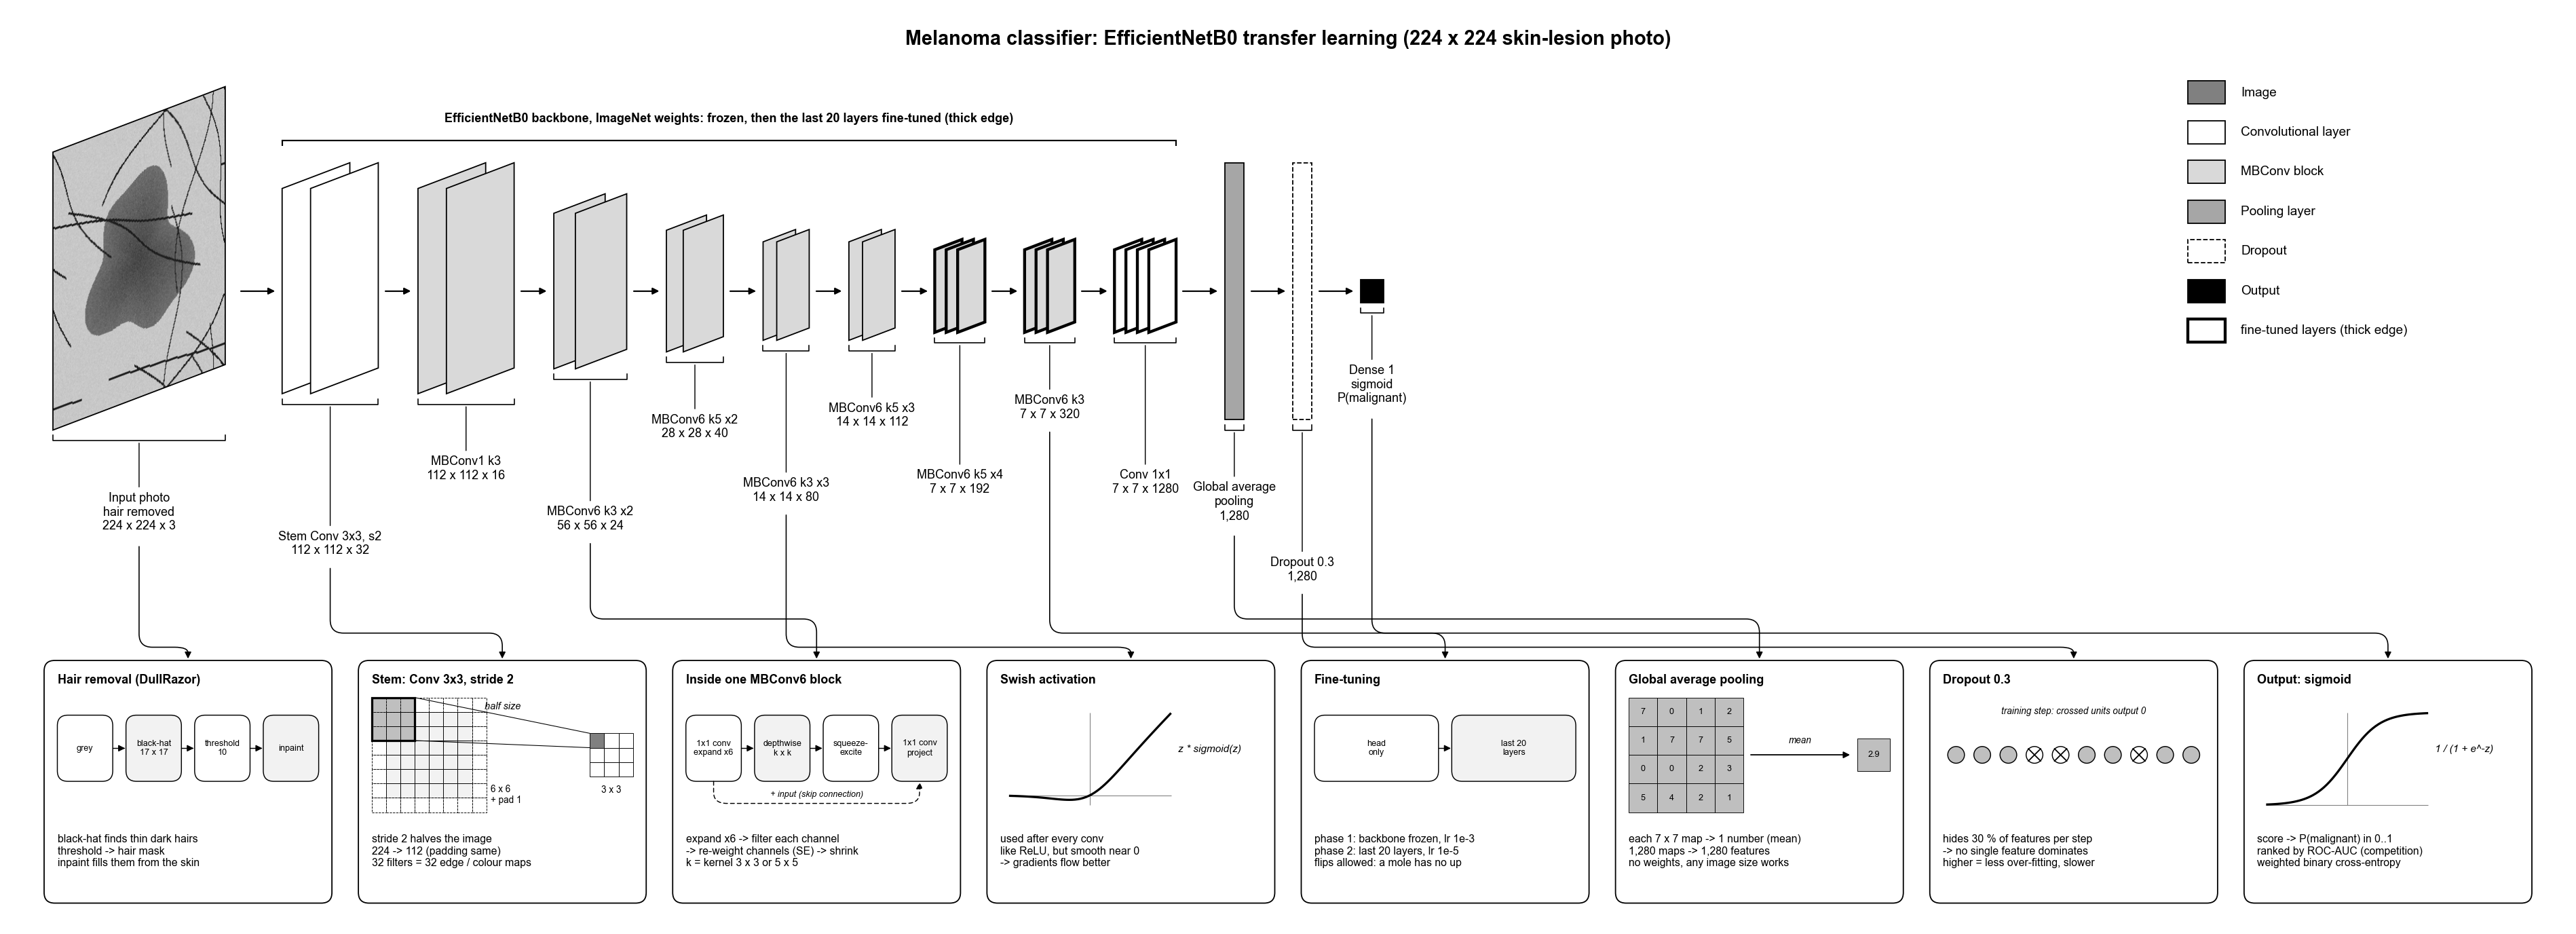

**Question:** Can a pre-trained CNN separate benign from malignant lesions with ~4,800 training images?

**1. Transfer learning** → EfficientNetB0 already learned edges, textures and shapes from 1.2M ImageNet photos. We reuse that visual vocabulary and train a small new head, like hiring an experienced photographer and teaching them dermatology instead of training someone who has never seen a picture.

**2. Sigmoid**

$$p = \sigma(z) = \frac{1}{1 + e^{-z}}$$
- $z$ → raw score from the network, any real number
- $\sigma$ → **sigmoid**: squashes $z$ into $(0, 1)$
- $p$ → predicted probability of malignant
- Analogy → a dimmer switch: however far you turn it, the light ends up between off and full

**3. Binary cross-entropy**

$$L = -w_y\big[\,y \log p + (1 - y) \log (1 - p)\,\big]$$
- $L$ → **binary cross-entropy**: the error for one image that training keeps shrinking
- $y$ → true label: 1 malignant, 0 benign
- $w_y$ → class weight of that label, from [7/11]
- $p$ → predicted probability from above
- Analogy → a weather forecaster: "99% sunny" on a rainy day costs far more than "60% sunny"; confident mistakes are punished hardest

**4. Training plan**
- **[1/2] Head** → backbone frozen, learning rate $10^{-3}$
- **[2/2] Fine-tune** → last `FINE_TUNE_LAST_N` backbone layers unfrozen, learning rate $10^{-5}$: 100× smaller, so it adjusts rather than overwrites what was learned
- **Online augmentation** → random flip / rotation / zoom inside the model: a slightly different image every epoch
- **Frozen BatchNorm** → the backbone keeps its ImageNet statistics, also while fine-tuning
- **Mixed precision** on GPU → float16 math, float32 output: faster, less memory

In [ ]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    keras.mixed_precision.set_global_policy('mixed_float16')
else:
    print('(!) No GPU found → training will be slow. Kaggle: Settings → Accelerator → GPU')
show_block('Outputs', {'TensorFlow': tf.__version__, 'GPUs': len(gpus),
                       'precision policy': keras.mixed_precision.global_policy().name})

In [ ]:
def make_dataset(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype('float32')))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda img, label: (tf.cast(img, tf.float32), label), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(X_tr_bal, y_tr_bal, training=True)
val_ds   = make_dataset(X_val, y_val, training=False)
show_block('Outputs', {'train batches': len(train_ds), 'val batches': len(val_ds)})

In [ ]:
def build_model(img_size=IMG_SIZE, dropout=0.3):
    base = keras.applications.EfficientNetB0(include_top=False, weights='imagenet',
                                             input_shape=(img_size, img_size, 3))
    base.trainable = False

    inputs  = keras.Input(shape=(img_size, img_size, 3))
    x       = keras.Sequential([layers.RandomFlip('horizontal_and_vertical'),
                                layers.RandomRotation(0.1),
                                layers.RandomZoom(0.1)], name='online_augmentation')(inputs)
    x       = base(x, training=False)
    x       = layers.GlobalAveragePooling2D()(x)
    x       = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation='sigmoid', dtype='float32')(x)
    return keras.Model(inputs, outputs, name='melanoma_effnetb0'), base


def make_metrics():
    return [keras.metrics.AUC(name='auc'), keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall')]


def make_callbacks():
    return [keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=3, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5, patience=2, min_lr=1e-7)]

In [ ]:
model, base_model = build_model()
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=make_metrics())
show_block('Outputs', {'parameters': f'{model.count_params():,}',
                       'trainable':  f'{sum(int(np.prod(w.shape)) for w in model.trainable_weights):,}'})

In [ ]:
print(f'[1/2] Train head · max {EPOCHS_HEAD} epochs')
history_head  = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                          callbacks=make_callbacks(), class_weight=class_weight, verbose=2)
best_head_auc = max(history_head.history['val_auc'])
head_weights  = [(variable, variable.numpy()) for variable in model.weights]
show_block('Outputs', {'best val AUC (head)': f'{best_head_auc:.4f}'})

In [ ]:
print(f'[2/2] Fine-tune last {FINE_TUNE_LAST_N} backbone layers · max {EPOCHS_FINE_TUNE} epochs')
base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_LAST_N]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5), loss='binary_crossentropy', metrics=make_metrics())
history_ft  = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE_TUNE,
                        callbacks=make_callbacks(), class_weight=class_weight, verbose=2)
best_ft_auc = max(history_ft.history['val_auc'])

if best_ft_auc < best_head_auc:
    for variable, value in head_weights:
        variable.assign(value)
show_block('Outputs', {'best val AUC (head)':      f'{best_head_auc:.4f}',
                       'best val AUC (fine-tune)': f'{best_ft_auc:.4f}',
                       'weights kept':             'fine-tune' if best_ft_auc >= best_head_auc else 'head'})

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metric in zip(axes, ['loss', 'auc', 'recall']):
    train_vals = history_head.history[metric] + history_ft.history[metric]
    val_vals   = history_head.history[f'val_{metric}'] + history_ft.history[f'val_{metric}']
    epochs     = np.arange(1, len(train_vals) + 1)
    ax.plot(epochs, train_vals, label='train')
    ax.plot(epochs, val_vals, label='validation')
    ax.axvline(len(history_head.history[metric]) + 0.5, color='grey', linestyle='--', label='start fine-tuning')
    ax.set_title(metric)
    ax.set_xlabel('epoch')
    ax.legend()
plt.tight_layout()
plt.show()

**What to look for** → validation AUC flattening while training AUC keeps rising = **overfitting** (memorising the training images). Early stopping keeps the best validation epoch of each phase.

In [ ]:
"""Optional · Set SAVE_MODEL = True in the top cell to write the model file."""
if SAVE_MODEL:
    model.save(MODEL_FILE)
    print(f'Saved → {MODEL_FILE}')
else:
    print(f'Preview · would save → {MODEL_FILE} · nothing written (SAVE_MODEL = False)')

# [9/11] Evaluation

Score the test set with a threshold picked on validation → ROC-AUC and the number of missed melanomas

**Question:** How good is the model, and what would that mean in a clinic?

**1. TPR and FPR**

$$\text{TPR} = \frac{TP}{TP + FN} \qquad \text{FPR} = \frac{FP}{FP + TN}$$
- $TP$ → melanomas flagged, $FN$ → melanomas missed
- $FP$ → benign moles flagged, $TN$ → benign moles cleared
- TPR → **recall / sensitivity**: share of melanomas caught
- FPR → share of benign moles sent to biopsy for nothing
- Analogy → airport security: TPR = share of real threats the scanner catches, FPR = share of harmless bags it pulls aside

**2. ROC-AUC** → area under the TPR-vs-FPR curve = the probability that a random malignant image scores higher than a random benign one. 0.5 = coin flip, 1.0 = perfect. It ignores the class ratio, so it carries over to the real 1.76% data.

**3. Youden's J**

$$J = \text{TPR} - \text{FPR}$$
- $J$ → **Youden's J**: the threshold with the highest $J$ on validation is reused unchanged on test
- Analogy → setting the scanner where "threats caught" minus "false alarms" is largest

**4. Precision**

$$\text{Precision} = \frac{TP}{TP + FP}$$
- Precision → of the moles we flag, the share that really are melanoma
- Depends on how common melanoma is: our test set is ~10.6% malignant, real data 1.76%
- Analogy → screen 1,000 people where 18 have melanoma: catching 16 with a 10% false-alarm rate also flags 98 healthy people → precision 16 / 114 = **14%**, even though recall is 89%

**Answer:** _after the first run_ → read test ROC-AUC and the false-negative count: a missed melanoma is the costly error.

In [ ]:
def predict_proba(model, X):
    return model.predict(make_dataset(X, np.zeros(len(X)), training=False), verbose=0).ravel()


p_val = predict_proba(model, X_val)
p_te  = predict_proba(model, X_te)

fpr_val, tpr_val, thr_val = roc_curve(y_val, p_val)
best_threshold = thr_val[np.argmax(tpr_val - fpr_val)]
y_pred_te      = (p_te >= best_threshold).astype(int)

display(pd.DataFrame({name: {'ROC-AUC':           roc_auc_score(y, p),
                             'average precision': average_precision_score(y, p),
                             'malignant share':   y.mean()}
                      for name, y, p in [('validation', y_val, p_val), ('test', y_te, p_te)]}).round(4))
show_block('Outputs', {'threshold (from validation)': f'{best_threshold:.3f}'})

In [ ]:
display(pd.DataFrame(classification_report(y_te, y_pred_te, target_names=['benign', 'malignant'],
                                           output_dict=True)).T.round(3))

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))

for name, y_true, p in [('validation', y_val, p_val), ('test', y_te, p_te)]:
    fpr, tpr, _ = roc_curve(y_true, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_true, p):.3f})')
    precision, recall, _ = precision_recall_curve(y_true, p)
    axes[1].plot(recall, precision, label=f'{name} (AP = {average_precision_score(y_true, p):.3f})')
axes[0].plot([0, 1], [0, 1], color='grey', linestyle='--', label='random')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate (recall)', title='ROC curve')
axes[1].axhline(y_te.mean(), color='grey', linestyle='--', label='random (test)')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision-recall curve')
axes[0].legend()
axes[1].legend()

for cls in [0, 1]:
    axes[2].hist(p_te[y_te == cls], bins=20, range=(0, 1), alpha=0.6, color=PALETTE[cls], label=CLASS_NAMES[cls])
axes[2].axvline(best_threshold, color='blue', linestyle='--', label=f'threshold {best_threshold:.2f}')
axes[2].set(xlabel='Predicted P(malignant)', ylabel='Test images', title='Predicted probabilities (test)')
axes[2].legend()

ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred_te),
                       display_labels=['benign', 'malignant']).plot(ax=axes[3], cmap='Greys', colorbar=False)
axes[3].set_title('Test confusion matrix')
axes[3].grid(False)

plt.tight_layout()
plt.show()

# [10/11] LIME

Check where the CNN looks → green on the lesion = trustworthy, green on hair or rulers = shortcut

**Question:** When the CNN says "malignant", is it looking at the lesion?

LIME explains one prediction at a time:

$$\xi(x) = \underset{g}{\arg\min}\; \mathcal{L}(f, g, \pi_x) + \Omega(g)$$
- $x$ → the image being explained, cut into **superpixels** (patches of similar colour)
- $f$ → our CNN, the black box
- $g$ → simple linear model: one weight per superpixel
- $\pi_x$ → closeness weight: perturbed images that still look like $x$ count more
- $\mathcal{L}$ → how badly $g$ imitates $f$ on those perturbed images
- $\Omega(g)$ → complexity penalty: keep only the top few superpixels
- Analogy → finding which ingredient makes a soup salty by cooking it again many times, each time leaving out random ingredients, and tasting
- Colours → green pushes towards malignant, red towards benign

**Answer:** _after the first run_ → trustworthy if green sits on the lesion; suspicious if it sits on hair, rulers, ink marks or dark corners.

In [ ]:
def classifier_fn(images):
    p = model.predict(np.asarray(images, dtype=np.float32), batch_size=64, verbose=0).ravel()
    return np.stack([1 - p, p], axis=1)


explainer = lime_image.LimeImageExplainer(random_state=SEED)

In [ ]:
case_masks = {
    'true positive':  (y_te == 1) & (y_pred_te == 1),
    'false negative': (y_te == 1) & (y_pred_te == 0),
    'false positive': (y_te == 0) & (y_pred_te == 1),
    'true negative':  (y_te == 0) & (y_pred_te == 0),
}
rng    = np.random.default_rng(SEED)
chosen = pd.DataFrame([{'case': name, 'test index': int(rng.choice(np.flatnonzero(mask)))}
                       for name, mask in case_masks.items() if mask.any()])
chosen['image_name']   = sample_df.loc[test_idx[chosen['test index']], 'image_name'].to_numpy()
chosen['true']         = pd.Series(y_te[chosen['test index']]).map(CLASS_NAMES)
chosen['P(malignant)'] = p_te[chosen['test index']].round(3)

empty_cases = [name for name, mask in case_masks.items() if not mask.any()]
if empty_cases:
    print('(!) No test images for: ' + ', '.join(empty_cases))
display(chosen)

In [ ]:
fig, axes = plt.subplots(len(chosen), 3, figsize=(13, 4.3 * len(chosen)), squeeze=False)
for row, (_, case) in enumerate(chosen.iterrows()):
    print(f"[{row + 1}/{len(chosen)}] LIME · {case['case']} · {case['image_name']}")
    if case['case'] == 'false negative':
        print('    (!) a melanoma the model sent home')
    i           = case['test index']
    explanation = explainer.explain_instance(X_te[i], classifier_fn, labels=(1,), hide_color=0,
                                             num_samples=LIME_SAMPLES, batch_size=64, random_seed=SEED)
    img_pos, mask_pos   = explanation.get_image_and_mask(1, positive_only=True, num_features=5, hide_rest=False)
    img_both, mask_both = explanation.get_image_and_mask(1, positive_only=False, num_features=10, hide_rest=False)

    axes[row, 0].imshow(X_te[i])
    axes[row, 0].set_title(f"{case['case']}\ntrue = {case['true']}, P(malignant) = {case['P(malignant)']:.2f}")
    axes[row, 1].imshow(mark_boundaries(img_pos / 255.0, mask_pos))
    axes[row, 1].set_title('Top 5 superpixels supporting "malignant"')
    axes[row, 2].imshow(mark_boundaries(img_both / 255.0, mask_both))
    axes[row, 2].set_title('Top 10: green = towards malignant, red = towards benign')
    for ax in axes[row]:
        ax.axis('off')

plt.suptitle('LIME explanations on the test set', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# [11/11] Submission

Predict the competition test set → preview by default, CSV only on request

**Question:** How would this score on the competition leaderboard?

**Answer:** Set `SAVE_SUBMISSION = True` to predict all 10,982 test images and write `submission.csv`. By default it previews 16 images and writes nothing.

In [ ]:
"""Optional · Set SAVE_SUBMISSION = True in the top cell to predict all test images and write the CSV."""
sub_df = test_df if SAVE_SUBMISSION else test_df.head(SUBMISSION_PREVIEW)
show_block('Inputs', {'mode':        'save' if SAVE_SUBMISSION else 'preview',
                      'test images': f'{len(sub_df):,} of {len(test_df):,}',
                      'output file': SUBMISSION_FILE})

In [ ]:
X_sub      = load_images(sub_df['image_name'], subset='test')
submission = pd.DataFrame({'image_name': sub_df['image_name'].to_numpy(), 'target': predict_proba(model, X_sub)})
display(submission.head(10))

if SAVE_SUBMISSION:
    submission.to_csv(SUBMISSION_FILE, index=False)
    print(f'Saved → {SUBMISSION_FILE}')
else:
    print(f'Preview · {len(submission)} rows · nothing written (SAVE_SUBMISSION = False)')

**Next steps**
- **All the data** → use all 32,542 benign images from a pre-resized copy of the competition JPEGs (256×256 datasets exist on Kaggle), so loading stays fast; add external malignant images (e.g. ISIC 2019)
- **Metadata** → combine age / sex / site with image features: age alone moves the rate from ~1% to 9.4%
- **Shortcut check** → predictions shouldn't follow image resolution / acquisition source
- **Bigger run** → higher resolution, k-fold ensemble, test-time augmentation